In [1]:
# install libraries

%pip install pandas sqlalchemy "psycopg[binary]" matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# import library

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, text

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [3]:
import pandas as pd

df = pd.read_csv(r"C:\CHURNIQ\SQL\psql telco_customers_data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (7043, 21)


,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.columns = df.columns.str.lower()

### Inspect columns and data types

In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

Dataset shape: (7043, 21)

Column names:
['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents', 'tenure', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod', 'monthlycharges', 'totalcharges', 'churn']

Data types:


,Data Type
customerid,object
gender,object
seniorcitizen,int64
partner,object
dependents,object
tenure,int64
phoneservice,object
multiplelines,object
internetservice,object
onlinesecurity,object


### Check missing values

In [6]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

,Missing Count,Missing Percentage
customerid,0,0.0
deviceprotection,0,0.0
totalcharges,0,0.0
monthlycharges,0,0.0
paymentmethod,0,0.0
paperlessbilling,0,0.0
contract,0,0.0
streamingmovies,0,0.0
streamingtv,0,0.0
techsupport,0,0.0


### Check duplicate records

In [7]:
print("Total duplicate rows:", df.duplicated().sum())

# Check duplicate customer IDs if the column exists
customer_id_col = next(
    (c for c in df.columns
     if c.lower() == "customerid"),
    
)

if customer_id_col:
    print(
        "Duplicate customer IDs:",
        df[customer_id_col].duplicated().sum()
    )
else:
    print("Customer ID column not found. Check Cell 7.")

Total duplicate rows: 0
Duplicate customer IDs: 0


### Clean column names and convert numeric columns

In [8]:
# Standardize column names for easier coding
df.columns = df.columns.str.strip()

# Convert TotalCharges to numeric if available
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"],
        errors="coerce"
    )

# Convert SeniorCitizen to a categorical-friendly integer
if "SeniorCitizen" in df.columns:
    df["SeniorCitizen"] = pd.to_numeric(
        df["SeniorCitizen"],
        errors="coerce"
    )

print("Data types after cleaning:")
display(df.dtypes.to_frame(name="Data Type"))

Data types after cleaning:


,Data Type
customerid,object
gender,object
seniorcitizen,int64
partner,object
dependents,object
tenure,int64
phoneservice,object
multiplelines,object
internetservice,object
onlinesecurity,object


### Check the churn distribution

In [9]:
print(df.columns)

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='object')


In [10]:
print("Churn column values:")

if "churn" in df.columns:
    display(df["churn"].value_counts(dropna=False))
else:
     print("Churn column not found. Check df.columns.")

Churn column values:


churn
No     5174
Yes    1869
Name: count, dtype: int64

### Visualize the churn distribution

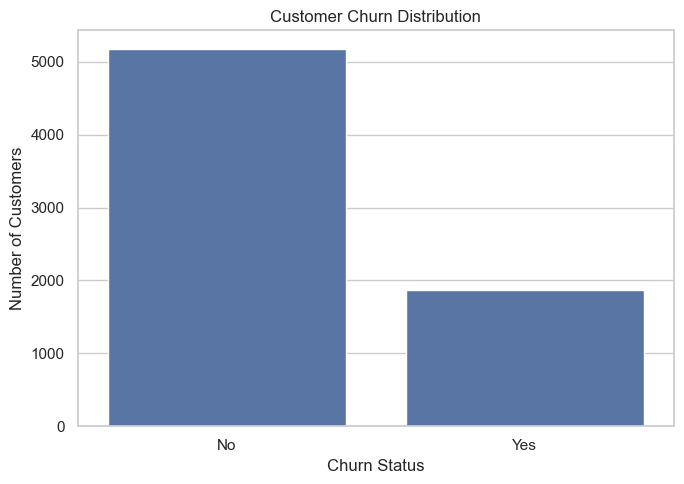

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

if "churn" in df.columns:
    plt.figure(figsize=(7, 5))

    ax = sns.countplot(
        data=df,
        x="churn"
    )

    ax.set_title("Customer Churn Distribution")
    ax.set_xlabel("Churn Status")
    ax.set_ylabel("Number of Customers")

    plt.tight_layout()
    plt.savefig("cust_churn_dist.png", dpi =300, bbox_inches= "tight")
    plt.show()
else:
    print("hi")

### Calculate the overall churn rate

In [12]:
if "churn" in df.columns:
    churn_rate = (
        df["churn"].astype(str).str.strip()
        .str.lower().eq("yes").mean() * 100
    )

    print(f"Overall churn rate: {churn_rate:.2f}%")

    print(
        f"Total customers: {len(df):,}"
    )
else:
    print("hi")

Overall churn rate: 26.54%
Total customers: 7,043


### Explore numerical feature

In [13]:
numeric_cols = df.select_dtypes(
    include="number"
).columns.tolist()

print("Numerical columns:", numeric_cols)

display(df[numeric_cols].describe().T)

Numerical columns: ['seniorcitizen', 'tenure', 'monthlycharges']


,count,mean,std,min,25%,50%,75%,max
seniorcitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
monthlycharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


### Compare tenure between churned and retained customers

,count,mean,median,min,max
churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


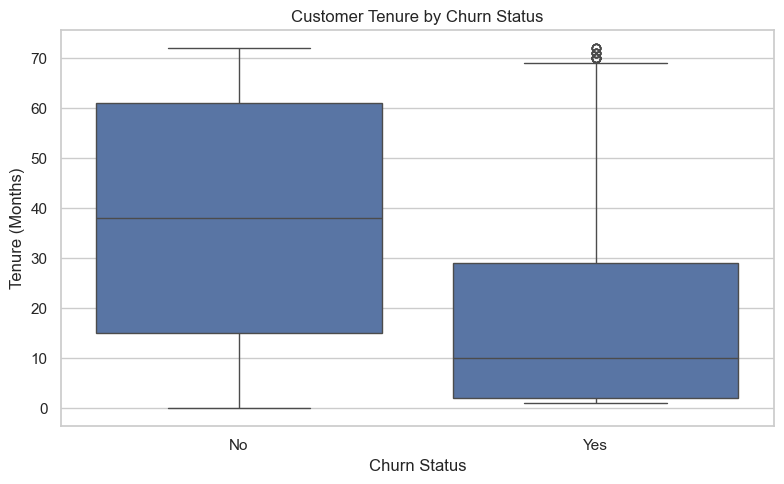

In [22]:
if {"churn", "tenure"}.issubset(df.columns):
    tenure_summary = (
        df.groupby("churn", observed=True)["tenure"]
        .agg(["count", "mean", "median", "min", "max"])
        .round(2)
    )

    display(tenure_summary)

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="churn",
        y="tenure"
    )

    plt.title("Customer Tenure by Churn Status")
    plt.xlabel("Churn Status")
    plt.ylabel("Tenure (Months)")
    plt.tight_layout()
    plt.savefig("cust_tenure_by_churn.png", dpi =300, bbox_inches= "tight")
    plt.show()

### Compare monthly charges by churn status

,mean,median,min,max
churn,,,,
No,61.27,64.43,18.25,118.75
Yes,74.44,79.65,18.85,118.35


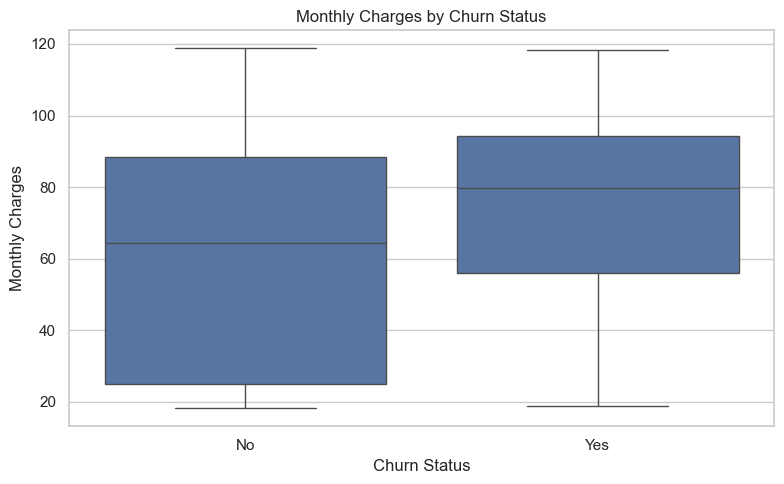

In [23]:
if {"churn", "monthlycharges"}.issubset(df.columns):
    charges_summary = (
        df.groupby("churn", observed=True)["monthlycharges"]
        .agg(["mean", "median", "min", "max"])
        .round(2)
    )

    display(charges_summary)

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="churn",
        y="monthlycharges"
    )

    plt.title("Monthly Charges by Churn Status")
    plt.xlabel("Churn Status")
    plt.ylabel("Monthly Charges")
    plt.tight_layout()
    plt.savefig("monthly_charges.png", dpi =300, bbox_inches= "tight")
    plt.show()
else:
    print("hi")

### PART 2 EDA

### Verify dataset columns

In [9]:
import pandas as pd

df = pd.read_csv(r"C:\CHURNIQ\SQL\psql telco_customers_data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (7043, 21)


,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [37]:


#  Verify dataset structure
# Purpose: Confirm the required columns are available before analyzing churn.

print("dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

required_columns = ["tenure", "contract", "churn"]
missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )
else:
    print("\nAll required columns are available.")



dataset shape: (7043, 22)

Column names:
['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents', 'tenure', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod', 'monthlycharges', 'totalcharges', 'churn', 'tenure_group']

All required columns are available.


### Analyze tenure by churn status

,count,mean,median,min,max
churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


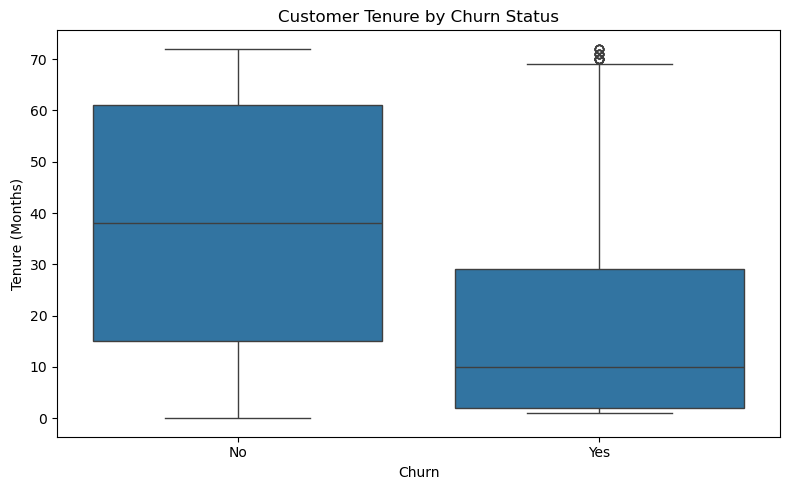

In [39]:

# Tenure analysis
# Purpose: Compare the length of customer relationships between customers who stayed and those who left.


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df["tenure"] = pd.to_numeric(
    df["tenure"], errors="coerce"
)

tenure_summary = (
    df.groupby("churn", dropna=False)["tenure"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)

display(tenure_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="churn", y="tenure")
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.savefig("cust_tenure_by_church_status.png", dpi =300, bbox_inches= "tight")

plt.show()


### Churn rate by tenure group

churn,No,Yes
tenure_group,,
0-12 months,52.56,47.44
13-24 months,71.29,28.71
25-48 months,79.61,20.39
49-60 months,85.58,14.42
60+ months,93.39,6.61


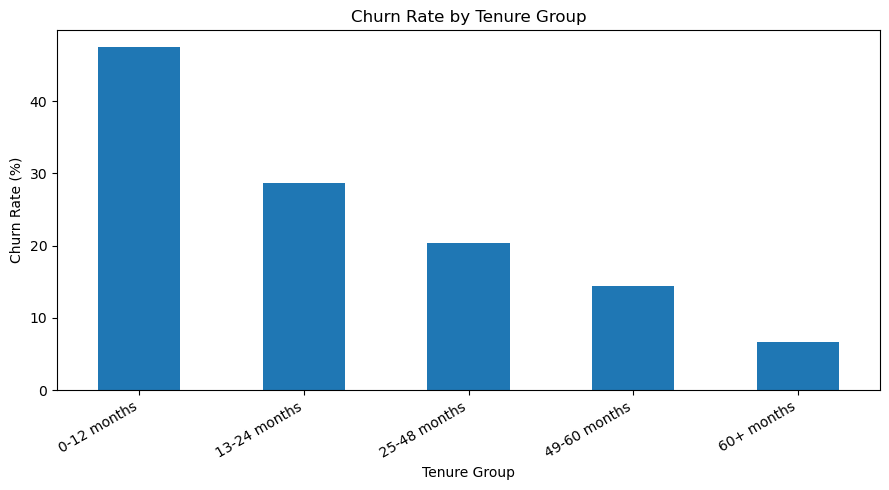

In [40]:

#  Tenure groups
# Purpose: Identify which customer lifecycle stages have the highest churn rates.

df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 60, float("inf")],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-60 months",
        "60+ months"
    ],
    include_lowest=True
)

tenure_churn = pd.crosstab(
    df["tenure_group"],
    df["churn"],
    normalize="index"
).mul(100)

display(tenure_churn.round(2))

if "Yes" in tenure_churn.columns:
    tenure_churn["Yes"].plot(
        kind="bar",
        figsize=(9, 5),
        title="Churn Rate by Tenure Group",
        ylabel="Churn Rate (%)",
        xlabel="Tenure Group"
    )
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig("cust_rate_by_tenure.png", dpi =300, bbox_inches= "tight")

    plt.show()


### Contract type versus churn

churn,No,Yes
contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


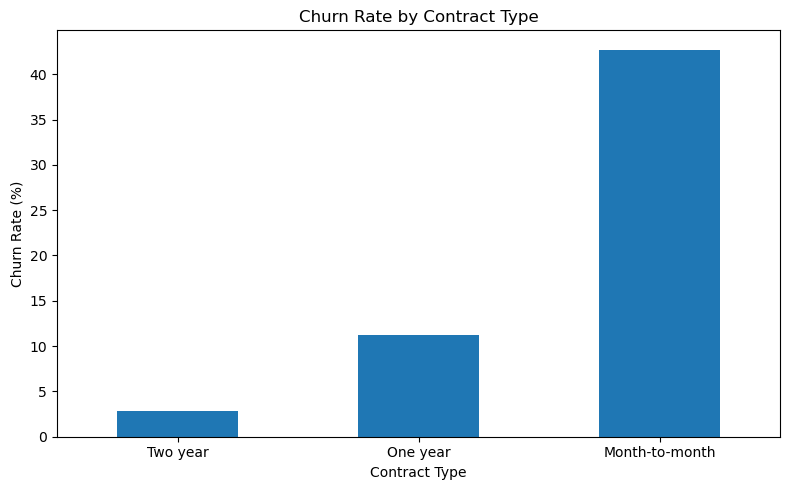

In [41]:

#  Contract analysis
# Purpose: Test whether churn rates differ between month-to-month and longer-term contracts.

contract_churn = pd.crosstab(
    df["contract"],
    df["churn"],
    normalize="index"
).mul(100)

display(contract_churn.round(2))

if "Yes" in contract_churn.columns:
    contract_churn["Yes"].sort_values().plot(
        kind="bar",
        figsize=(8, 5),
        title="Churn Rate by Contract Type",
        ylabel="Churn Rate (%)",
        xlabel="Contract Type"
    )
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig("cust_rate_by_contract_type.png", dpi =300, bbox_inches= "tight")

    plt.show()


churn,No,Yes
contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


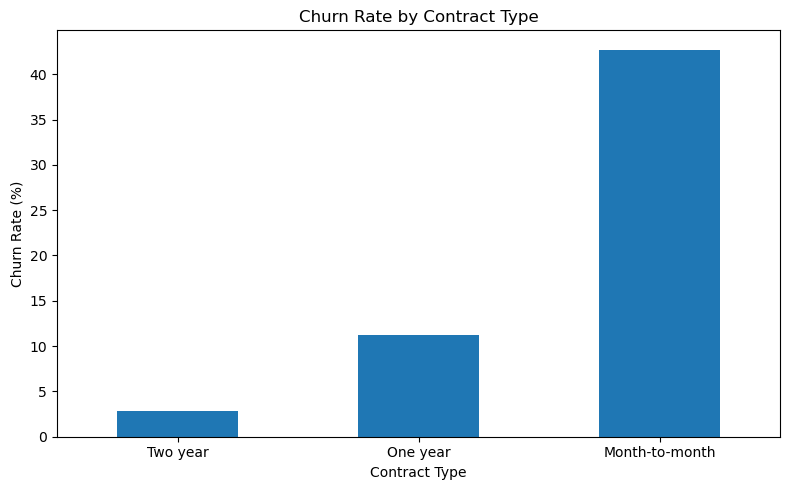

In [34]:

#  Contract analysis
# Purpose: Test whether churn rates differ between month-to-month and longer-term contracts.

contract_churn = pd.crosstab(
    df["contract"],
    df["churn"],
    normalize="index"
).mul(100)

display(contract_churn.round(2))

if "Yes" in contract_churn.columns:
    contract_churn["Yes"].sort_values().plot(
        kind="bar",
        figsize=(8, 5),
        title="Churn Rate by Contract Type",
        ylabel="Churn Rate (%)",
        xlabel="Contract Type"
    )
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


### Analyze monthly and total charges

monthlycharges        totalcharges         
                mean median         mean   median
churn                                            
No             61.27  64.43      2555.34  1683.60
Yes            74.44  79.65      1531.80   703.55

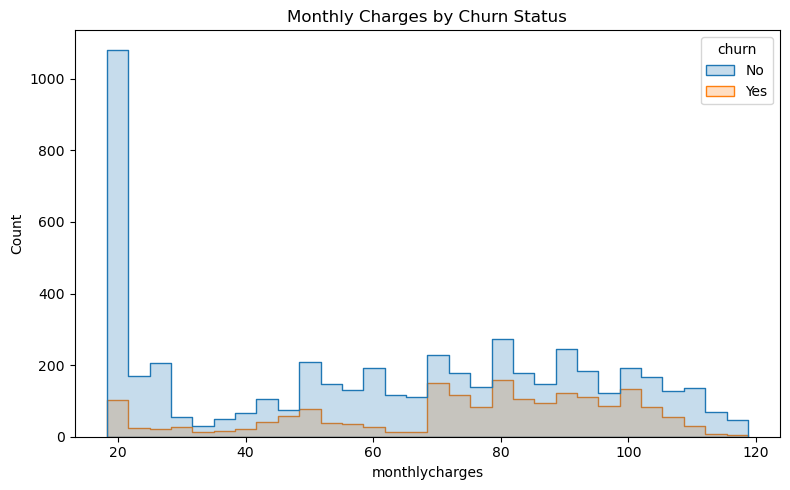

In [42]:

#  Billing analysis
# Purpose: Understand whether billing patterns differ between customers who churn and those who stay.

for col in ["monthlyCharges", "totalcharges"]:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        )

billing_columns = [
    col for col in ["monthlycharges", "totalcharges"]
    if col in df.columns
]

billing_summary = (
    df.groupby("churn", dropna=False)[billing_columns]
      .agg(["mean", "median"])
      .round(2)
)

display(billing_summary)

if "monthlycharges" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(
        data=df,
        x="monthlycharges",
        hue="churn",
        bins=30,
        element="step"
    )
    plt.title("Monthly Charges by Churn Status")
    plt.tight_layout()
    plt.savefig("cust_monthly_charges_by_churn.png", dpi =300, bbox_inches= "tight")

    plt.show()


### Analyze service adoption and churn


churn rate by internetservice:


churn,No,Yes
internetservice,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


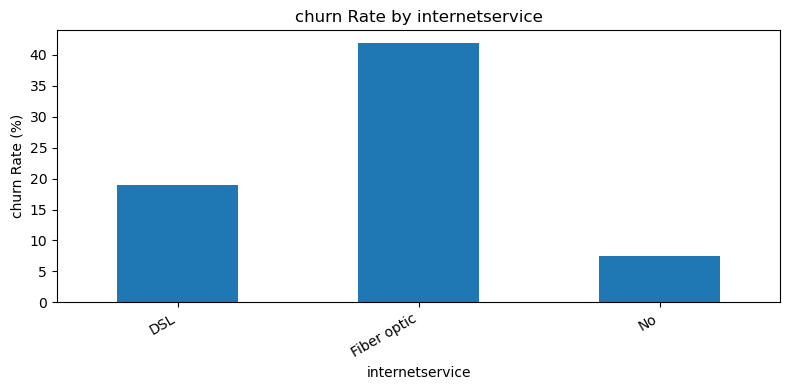


churn rate by onlinesecurity:


churn,No,Yes
onlinesecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


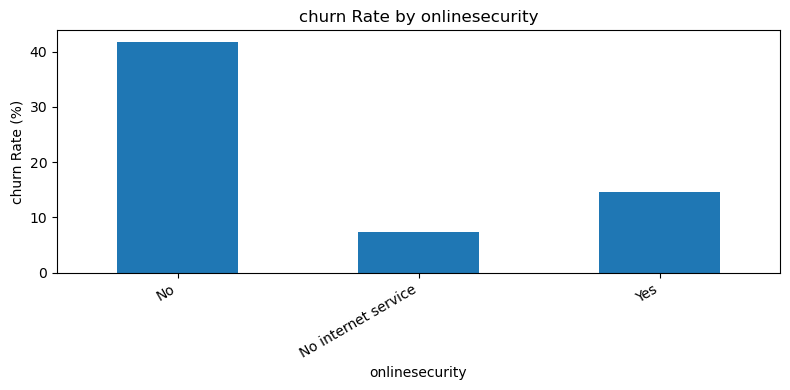


churn rate by onlinebackup:


churn,No,Yes
onlinebackup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53


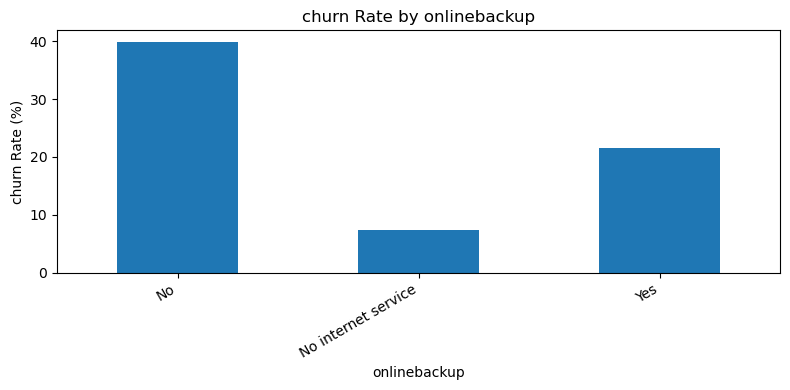


churn rate by deviceprotection:


churn,No,Yes
deviceprotection,,
No,60.87,39.13
No internet service,92.60,7.40
Yes,77.50,22.50


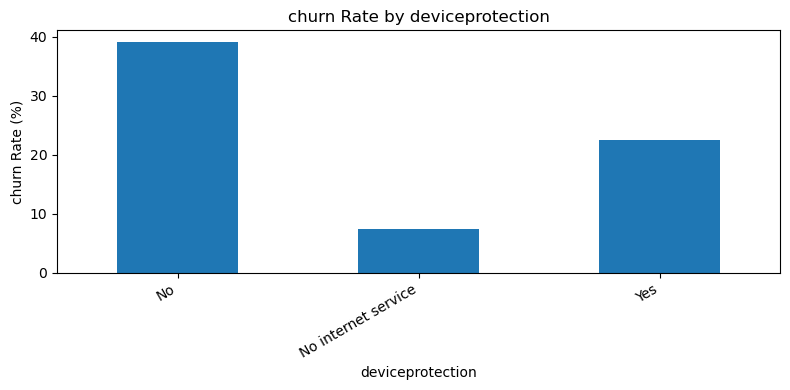


churn rate by techsupport:


churn,No,Yes
techsupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


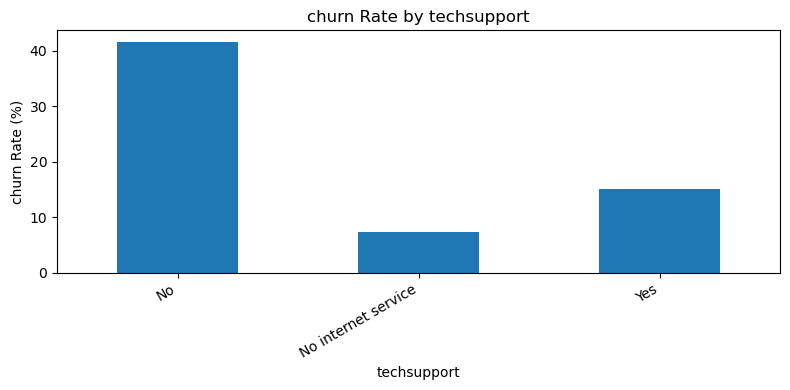


churn rate by streamingtv:


churn,No,Yes
streamingtv,,
No,66.48,33.52
No internet service,92.60,7.40
Yes,69.93,30.07


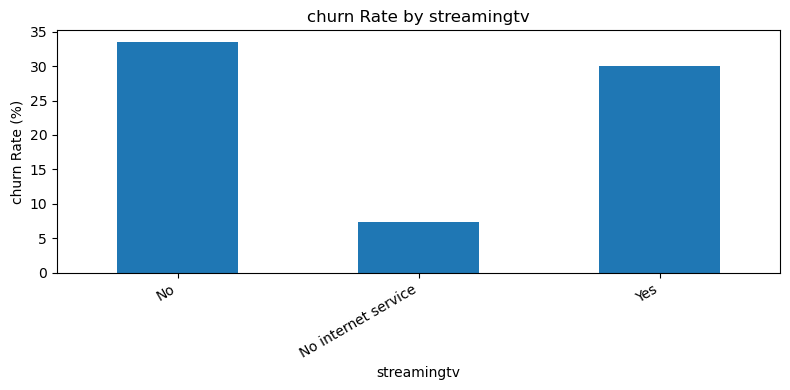


churn rate by streamingmovies:


churn,No,Yes
streamingmovies,,
No,66.32,33.68
No internet service,92.60,7.40
Yes,70.06,29.94


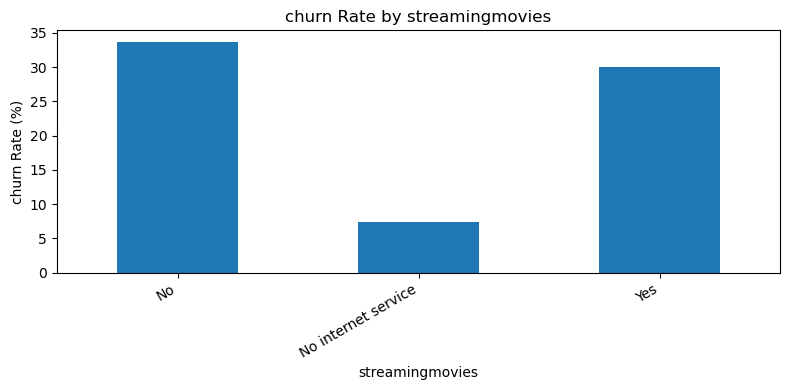

In [50]:

#  Service adoption analysis
# Purpose: Examine whether subscriptions to additional services are associated with different churn rates.

service_columns = [
    "internetservice",
    "onlinesecurity",
    "onlinebackup",
    "deviceprotection",
    "techsupport",
    "streamingtv",
    "streamingmovies"
]

available_services = [
    col for col in service_columns
    if col in df.columns
]

for col in available_services:
    print(f"\nchurn rate by {col}:")

    result = pd.crosstab(
        df[col],
        df["churn"],
        normalize="index"
    ).mul(100)

    display(result.round(2))

    if "Yes" in result.columns:
        result["Yes"].plot(
            kind="bar",
            figsize=(8, 4),
            title=f"churn Rate by {col}",
            ylabel="churn Rate (%)"
        )
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.savefig("cust_churn_rate_internetservice.png", dpi =300, bbox_inches= "tight"),
        plt.savefig("cust_churn_raterate_onlinesecurity.png", dpi =300, bbox_inches= "tight"),
        plt.savefig("cust_churn_rate_onlinebackup.png", dpi =300, bbox_inches= "tight"),
        plt.savefig("cust_churn_rate_deviceprotection.png", dpi =300, bbox_inches= "tight"),
        plt.savefig("cust_churn_rate_techsupport.png", dpi =300, bbox_inches= "tight"),
        plt.savefig("cust_churn_rate_streamingtv.png", dpi =300, bbox_inches= "tight"),
        plt.savefig("cust_churn_rate_streamingmovies.png", dpi =300, bbox_inches= "tight")

        plt.show()


In [28]:
df.columns

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn',
       'tenure_group'],
      dtype='object')

### Investigate complaints and support-related fields

In [31]:
# Purpose: Determine whether your dataset contains actual complaint records or only service-support indicators.

#  Complaint and support field discovery

complaint_keywords = [
    "complaint", "ticket", "incident", "fault"
]

complaint_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in complaint_keywords
    )
]

support_columns = [
    col for col in ["techsupport", "onlinesecurity"]
    if col in df.columns
]

print("Potential complaint fields:", complaint_columns)
print("Support-related proxies:", support_columns)

if complaint_columns:
    for col in complaint_columns:
        print(f"\nAnalysis for {col}:")

        if df[col].nunique(dropna=True) <= 15:
            result = pd.crosstab(
                df[col].fillna("missing"),
                df["churn"],
                normalize="index"
            ).mul(100)

            display(result.round(2))
        else:
            numeric = pd.to_numeric(
                df[col], errors="coerce"
            )

            if numeric.notna().any():
                display(
                    df.assign(_value=numeric)
                      .groupby("churn")["_value"]
                      .agg(["mean", "median", "count"])
                      .round(2)
                )
else:
    print(
        "No dedicated complaint or ticket fields found. "
        "Use actual complaint data from another source "
        "if complaint impact must be measured."
    )


Potential complaint fields: []
Support-related proxies: ['techsupport', 'onlinesecurity']
No dedicated complaint or ticket fields found. Use actual complaint data from another source if complaint impact must be measured.


### Correlation analysis

,seniorcitizen,tenure,monthlycharges,totalcharges
seniorcitizen,1.00,0.02,0.22,0.10
tenure,0.02,1.00,0.25,0.83
monthlycharges,0.22,0.25,1.00,0.65
totalcharges,0.10,0.83,0.65,1.00


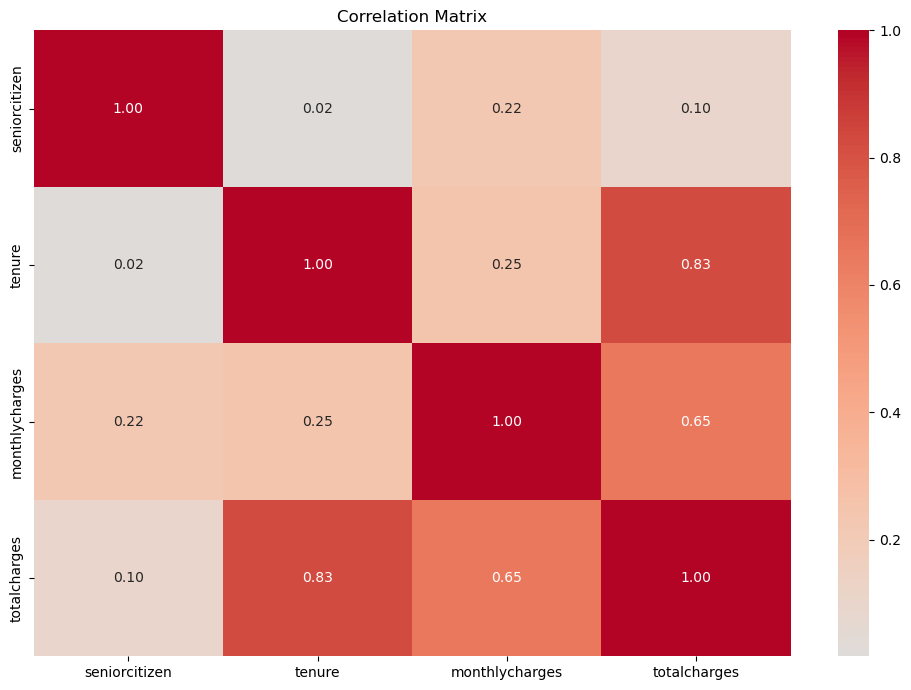

In [51]:

#  Numeric correlation matrix
#  Purpose: Examine linear relationships among numeric variables before creating the model features.

numeric_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

if len(numeric_columns) >= 2:
    correlation_matrix = df[numeric_columns].corr()

    display(correlation_matrix.round(2))

    plt.figure(figsize=(10, 7))
    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        center=0
    )
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.savefig("cust_churn_correlation_matrix.png", dpi =300, bbox_inches= "tight")

    plt.show()
else:
    print("Not enough numeric columns for correlation analysis.")
